In [2]:
#Loading Necessary Packages
# This is used to access Python interactive environment. This way we can feed input and receive output as we code.
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import pandas as pd #this package will be used for managing dataframes and excel sheets

## How to load your code dataframe to this sheet?

Copy this to Jupyter Notebook where you created your data frame:

%store longest_cat_df 

OR 

save your dataframe as excel_sheet: 

longest_cat_df.to_excel("longest_cataplexy.xlsx", index=False) 

In [3]:
#%store -r longest_cat_df #loading your data frame from previous document

replace longest_cat_df or any variables with your own data frame name! :) 

In [4]:
longest_cat_df = pd.read_excel("longest_cataplexy.xlsx", "Sheet1")

In [5]:
longest_cat_df #displaying your data frame (write the name of your data frame here)

,Mouse ID,Longest duration (epochs)
0,607_KO,8
1,305_KO,11
2,299_KO,9
3,306_KO,4
4,307_WT,0
5,308_WT,0
6,309_WT,0


# Installing Packages: Matplotlib


don't have to do this step if you alreafy have group column!

In [6]:
#The code below adds a new column "Group" 
#The code then looks at last "string" (ending of a each individual mouse ID)
#It will labeled anything that has KO in it as Narcoleptic vs. WT as Wild-Type

#longest_cat_df["Mouse ID"] - select your mouseID column
#.str.split("_") Splits each ID at the underscore
#str[-1] Takes the last part of each split ID (-1 means last item)
#.map({"WT": "Wild-Type","KO": "Narcoleptic",}) - creates identity for each mouse (group name)

longest_cat_df["Group"] = longest_cat_df["Mouse ID"].str.split("_").str[-1].map({
    "WT": "Wild-Type",
    "KO": "Narcoleptic",
})

longest_cat_df

,Mouse ID,Longest duration (epochs),Group
0,607_KO,8,Narcoleptic
1,305_KO,11,Narcoleptic
2,299_KO,9,Narcoleptic
3,306_KO,4,Narcoleptic
4,307_WT,0,Wild-Type
5,308_WT,0,Wild-Type
6,309_WT,0,Wild-Type


# Making proper graphs: Box and Whiskers

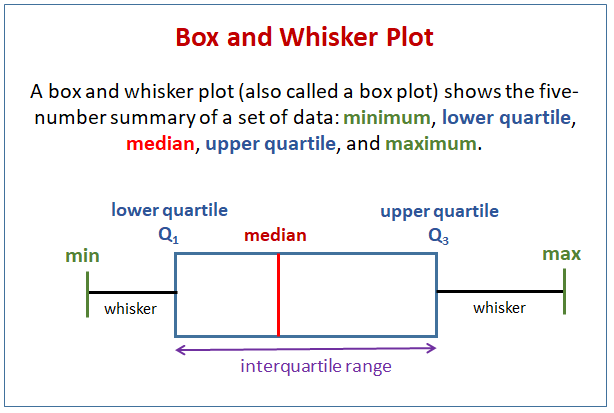

In [7]:
import seaborn as sns # this package will be used to add aesthetics for data visualization 
!pip install seaborn #installing the package 

import matplotlib.pyplot as plt #another library for plotting graphs 

Documentations: https://seaborn.pydata.org/generated/seaborn.catplot.html

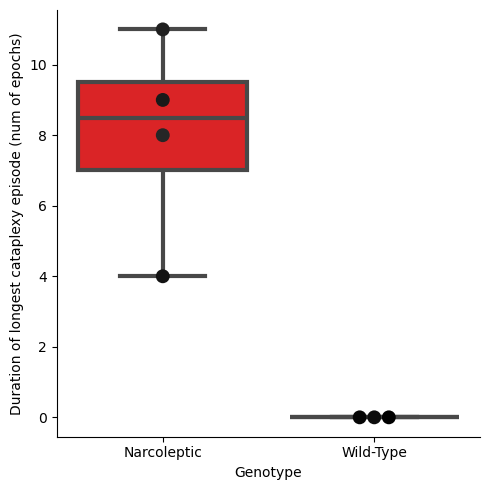

In [18]:
NarcolepticvsWT = sns.catplot(data = longest_cat_df, #choose correct data frame
                      x = "Group", y = "Longest duration (epochs)",  #choose what is shown on x vs. y axis                     
                      kind = "box", # make a boxplot #kind = "violin" as another example
                      hue = "Group",  #Assign different color to each genotype
                      palette = {"Narcoleptic":"#E41A1C", "Wild-Type": "#377EB8"}, #set color for each group
                      linewidth= 3, #set line width of box plot   
                      saturation = 0.9 #color intensity
                      
                     )


            
NarcolepticvsWT.map_dataframe(sns.swarmplot, data = longest_cat_df,  #choose correct data frame
                      x = "Group", #choose what is shown on x vs. y axis                     
                      y = "Longest duration (epochs)", 
                      hue = "Mouse ID",        # split the points by mouseID
                      palette="dark:black",     # color points in black
                      size=10   )                # set the size of points  

NarcolepticvsWT.set_axis_labels("Genotype", "Duration of longest cataplexy episode (num of epochs)")
#plt.ylim(0, 100) -> set y-axis limit
# Save the plot
plt.savefig("NarcolepticvsWT.png", 
            format = "png", 
            dpi = 600
           )
plt.show()

# Statistics in Python:

The last step in our data exploration journey is **performing statistical analysis**. This is where we test whether the differences we see between our groups are actually meaningful, or if they might have happened just by chance. We can calculate these tests directly in Python.

You can use this chart to guide you for the future:

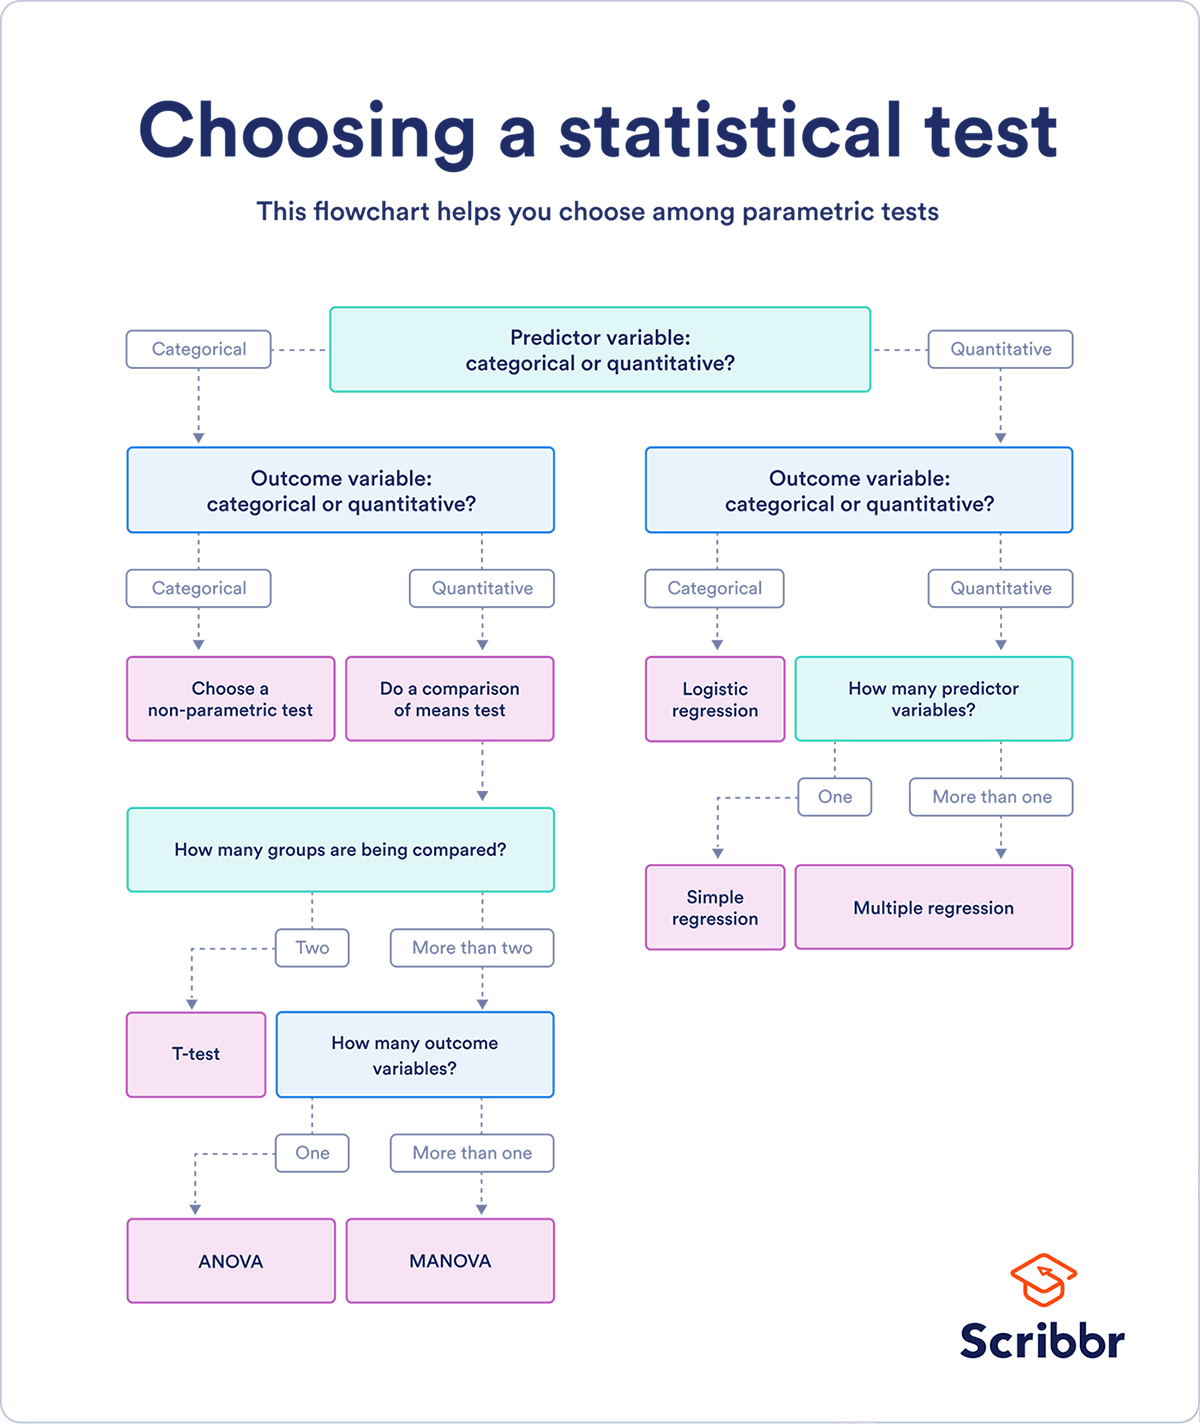

Link: https://www.scribbr.com/statistics/statistical-tests/

# Subset Our Data for Statistical Analysis:

In [9]:
#Select Column of Data with Loc (subset of WT vs. OXKO mice)

narcoleptic = longest_cat_df.loc[longest_cat_df.Group == "Narcoleptic", "Longest duration (epochs)"]

wt = longest_cat_df.loc[longest_cat_df.Group == "Wild-Type", "Longest duration (epochs)"]

narcoleptic
wt

0     8
1    11
2     9
3     4
Name: Longest duration (epochs), dtype: int64

4    0
5    0
6    0
Name: Longest duration (epochs), dtype: int64

## Importing Statistics Library 

In [10]:
from scipy import stats #this package will be used for statistical analysis 

In [12]:
#for dependent t-test (within genotype, for example), call stats.ttest_rel
#for anova call (more than 2 groups): f_stat, p_val = stats.f_oneway(group_a, group_b, group_c)
t_stat, p_value = stats.ttest_ind(wt, narcoleptic, equal_var = False) #applying our stats test
print("p-value is ", p_value)

p-value is  0.012227519436812334


# How to interpret statistical analysis?

In research, we often use a threshold of p < 0.05 to decide whether an effect is considered statistically significant.

- If **p < 0.05** → we say the difference is statistically significant, meaning it is unlikely to have occurred by chance.

- If **p ≥ 0.05** → we say the difference is not statistically significant, meaning we don’t have enough evidence to conclude there’s a real effect.


# How to results from statistical analysis to our plot? 

In [13]:
!pip install statannotations
from statannotations.Annotator import Annotator

  Using cached statannotations-0.7.2-py3-none-any.whl.metadata (7.7 kB)
Using cached statannotations-0.7.2-py3-none-any.whl (39 kB)


Working with Annotator:

1) Create an Annotator object where:

annotator = Annotator(plot_name, pairs, data= your_data_frame, x="", y="", order=order)

- **plot_name** = the Seaborn/Matplotlib plot you already made.

- **pairs** = tells it which groups to compare (e.g., "Wild-Type" vs "Narcoleptic").

- **data** = your DataFrame with the values.

- **x="", y=""** = which columns hold the groups and the variable you’re testing.

- **order** = makes sure the groups are shown in the correct order on the x-axis.

2) Set up which test will be run and how the result will be shown

annotator.configure(test="", text_format="", loc="")

- **test=" "** = input the name of your statistical test.

- **text_format="star"** → show stars instead of raw p-values (ns, *, **, ***). (text_format="simple" for raw p-values)

- **loc="outside/inside"** → place the stars above the bar connecting the groups.

3) Run the test and draw the annotation (the horizontal line + stars) on your plot. 

annotator.apply_and_annotate()

<Figure size 600x400 with 0 Axes>

<Axes: xlabel='Group', ylabel='Longest duration (epochs)'>

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Wild-Type vs. Narcoleptic: t-test independent samples, P_val:5.876e-03 t=-4.593e+00


(<Axes: xlabel='Group', ylabel='Longest duration (epochs)'>,
 [<statannotations.Annotation.Annotation at 0x744af2cbf920>])

Text(41.972222222222214, 0.5, 'Longest cataplexy bout duration (epochs a.u)')

Text(0.5, 1.0, 'Longest cataplexy duration across Wild-Type and Narcoleptic Mice')

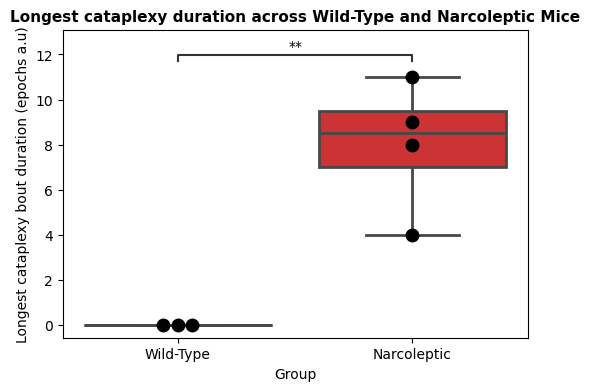

In [17]:
# Use your existing DataFrame
#Subset columns with your Group and Parameters 
graphing_df_with_stats = longest_cat_df[["Group", "Longest duration (epochs)"]].copy()

#Optional: enforce group order (WT first, Narcoleptic second)
order = ["Wild-Type", "Narcoleptic"]

plt.figure(figsize=(6,4)) #set size of your final figure 
wt_narcoleptic_data_plot = sns.boxplot( #choose correct data frame
    data= graphing_df_with_stats, x="Group", y="Longest duration (epochs)", #choose what will go into x vs. y. axis
    hue = "Group", #color by our genotype
    order=order, #refer to the order defined above 
    palette={"Narcoleptic":"#E41A1C", "Wild-Type":"#377EB8"}, #choose colors of your plot
    linewidth=2
)

sns.swarmplot(
    data=graphing_df_with_stats,
    x="Group",
    y="Longest duration (epochs)",
    order=order,
    color="black",
    size=10,
    ax=wt_narcoleptic_data_plot,
    zorder=3,
)

# Define which groups to compare (must match x labels)
pairs = [(order[0], order[1])]

# Automatic stats + annotation (Independent (t-test_ind) t-test; prints stars)
annotator = Annotator(wt_narcoleptic_data_plot, pairs, data= graphing_df_with_stats, x="Group", y="Longest duration (epochs)", order=order)
annotator.configure(test="t-test_ind", text_format="star", loc="inside")
annotator.apply_and_annotate()

#Alternatively to 3 lines above
#annotator.set_pvalues([your p-value number goes here])
#annotator.annotate() 

# Axes cosmetics
wt_narcoleptic_data_plot.set_ylabel("Longest cataplexy bout duration (epochs a.u)")
plt.title("Longest cataplexy duration across Wild-Type and Narcoleptic Mice", 
          fontsize=11, fontweight="bold")

#plt.tight_layout()

# Save the plot
plt.savefig("graphing_df_with_stats.png", 
            format = "png", 
            dpi = 600
           )
plt.show()

## How to save your plot? 

In [ ]:
# Save the plot
plt.savefig("graphing_df_with_stats.png", 
            format = "png", 
            dpi = 600
           )

# Additional Graphs (for your own interest) and Information:

## If you want to try and plot hypnogram for WT vs. OX-KO mice:

In [ ]:
import matplotlib.pyplot as plt

#for stages varuable, you need to figure out how to input subset of your excel sheet here. 
stages = ["W", "W", "NR", "NR", "W", "W", "C", "C", "C", "C", "W"] 
epoch_seconds = 30  # Use 5 for your mouse recordings if each row is 5 seconds.

stage_levels = {"NR": 0, "R": 1, "C": 2, "W": 3} #define stages that you will plot in the hypnogram
values = [stage_levels[stage] for stage in stages]
time_edges = [i * epoch_seconds for i in range(len(stages) + 1)]

fig, ax = plt.subplots(figsize=(8, 3))
ax.stairs(values, time_edges, baseline=None, color="black")
ax.set_yticks([0, 1, 2, 3], ["NREM", "REM", "Cataplexy", "Wake"])
ax.set_xlabel("Time (s)")
ax.set_title("Hypnogram")
fig.tight_layout()
plt.show()

For your graphical abstracts, you can figure out how to make one of those based on your column A data! :) 

## How to add additional columns of WT mice (with 0s) to your data frame: 

In [ ]:
#DO NOT RUN 
#Sample code to add WT mice with 0s as a parameter if looking at cataplexy

wt_mice = pd.DataFrame({
    "Mouse ID": ["522_WT", "577_WT", "555_WT"],
    "Longest duration (epochs)": [0, 0, 0],
})

longest_cat_df = pd.concat([longest_cat_df, wt_mice], ignore_index=True)
display(longest_cat_df)